In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
out = "./results/tolerance/ffd"


pd_ris = pd.read_csv(f"{out}/LeastSquares_100.csv")



In [3]:
labels = list(set(pd_ris['directions'].values))
num_directions = list(set(pd_ris['gamma'].values))
num_directions.sort()

In [4]:
labels = labels[::-1]

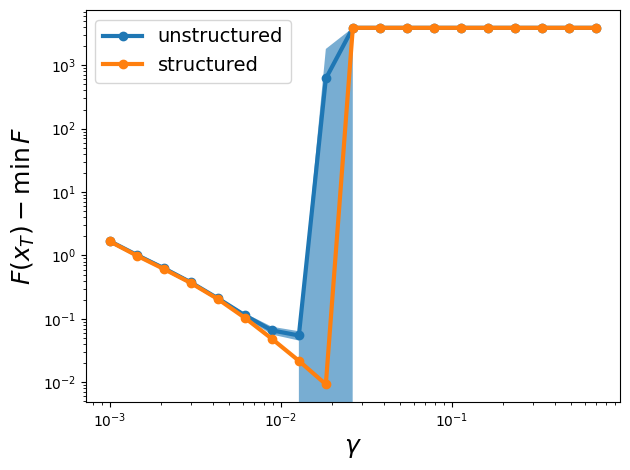

In [5]:

label_map = {
    'spherical' : 'unstructured',
    'householder' : 'structured',
}

fig, ax = plt.subplots()
for label in labels:
    mu_err  = pd_ris[pd_ris['directions'] == label ]['mu_last_val'].values[:-1]
    std_err = pd_ris[pd_ris['directions'] == label ]['std_last_val'].values[:-1]
    ax.plot(num_directions[:-1], mu_err, 'o-', lw=3, label=label_map[label])
    ax.fill_between(num_directions[:-1], mu_err - std_err, mu_err + std_err, alpha=0.6 )
    
#ax.axhline(1e-1, linestyle='--')
ax.set_xscale('log')
ax.set_yscale("log")
ax.set_ylabel("$F(x_T) - \\min \\, F$",fontsize=18)
ax.set_xlabel("$\\gamma$", fontsize=18)
ax.legend(fontsize=14)
fig.tight_layout()
fig.savefig("./stepsize.png", bbox_inches='tight')

In [40]:
num_directions[ np.argmin(pd_ris[pd_ris['directions'] == 'spherical' ]['mu_last_val'].values[:-1]) ]

0.0127427498570313

In [41]:
num_directions[ np.argmin(pd_ris[pd_ris['directions'] == 'householder' ]['mu_last_val'].values[:-1]) ]

0.0183298071083243

In [6]:
mu_sph, std_sph = [], []
with open("./results/conv_speed/ffd/LeastSquares_100_spherical_best", 'r') as f:
    for line in f.readlines():
        splitted = line.split(",")
        mu_sph.append(float(splitted[0]))
        std_sph.append(float(splitted[1]))
mu_sph, std_sph = np.array(mu_sph), np.array(std_sph)

In [7]:
mu_h, std_h = [], []
with open("./results/conv_speed/ffd/LeastSquares_100_householder_best", 'r') as f:
    for line in f.readlines():
        splitted = line.split(",")
        mu_h.append(float(splitted[0]))
        std_h.append(float(splitted[1]))
        
mu_h, std_h = np.array(mu_h), np.array(std_h)

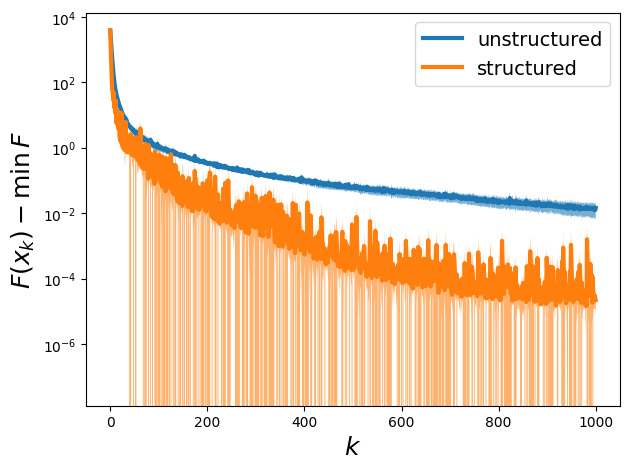

In [8]:
fig, ax = plt.subplots()

ax.plot(range(len(mu_sph)), mu_sph, '-', lw=3, label='unstructured')
ax.fill_between(range(len(mu_sph)), mu_sph - std_sph, mu_sph + std_sph, alpha=0.6)
ax.plot(range(len(mu_h)), mu_h, '-', lw=3, label='structured')
ax.fill_between(range(len(mu_h)), mu_h - std_h, mu_h + std_h, alpha=0.6)


ax.set_xlabel("$k$", fontsize=18)
ax.set_ylabel("$F(x_k) - \\min \\, F$", fontsize=18)
ax.set_yscale('log')
ax.legend(fontsize=14)
fig.tight_layout()
fig.savefig("./conv_speed.png", bbox_inches='tight')